# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

## 0. Comprobación

In [117]:
import pandas as pd
import matplotlib as plt

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [118]:
pd.read_csv("Matches.csv")

/var/folders/df/3s7cdjfx0fjcq2kbs1zx_bbm0000gn/T/ipykernel_41099/3098608143.py:1: DtypeWarning: Columns (2: MatchTime) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv("Matches.csv")


,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,...,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
0,F1,2000-07-28,NaN,Marseille,Troyes,1686.34,1586.57,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1,2000-07-28,NaN,Paris SG,Strasbourg,1714.89,1642.51,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,F2,2000-07-28,NaN,Wasquehal,Nancy,1465.08,1633.80,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,F1,2000-07-29,NaN,Auxerre,Sedan,1635.58,1624.22,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,F1,2000-07-29,NaN,Bordeaux,Metz,1734.34,1673.11,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238853,B1,2026-09-03,19:30:00,Anderlecht,Kortrijk,1527.89,1372.40,3.0,6.0,0.0,...,2.40,-1.00,1.80,2.00,NaN,NaN,NaN,NaN,NaN,NaN
238854,B1,2026-09-03,19:30:00,Gent,Oud-Heverlee Leuven,1533.21,1402.94,9.0,10.0,0.0,...,2.10,-1.00,2.08,1.73,NaN,NaN,NaN,NaN,NaN,NaN
238855,F1,2026-09-03,19:45:00,Toulouse,Lille,1654.07,1789.37,2.0,8.0,4.0,...,1.80,0.25,1.98,1.88,NaN,NaN,NaN,NaN,NaN,NaN
238856,SC0,2026-09-03,19:45:00,Hibernian,Hearts,1433.89,1494.62,6.0,9.0,6.0,...,1.98,0.00,1.85,2.00,NaN,NaN,NaN,NaN,NaN,NaN


**1.2** ¿Cuántas filas y columnas tiene?

In [119]:
df = pd.read_csv("Matches.csv")

df.shape



/var/folders/df/3s7cdjfx0fjcq2kbs1zx_bbm0000gn/T/ipykernel_41099/794355908.py:1: DtypeWarning: Columns (2: MatchTime) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Matches.csv")


(238858, 48)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [120]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 238858 entries, 0 to 238857
Data columns (total 48 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Division     238858 non-null  str    
 1   MatchDate    238858 non-null  str    
 2   MatchTime    107373 non-null  str    
 3   HomeTeam     238858 non-null  str    
 4   AwayTeam     238858 non-null  str    
 5   HomeElo      149898 non-null  float64
 6   AwayElo      149829 non-null  float64
 7   Form3Home    237334 non-null  float64
 8   Form5Home    237323 non-null  float64
 9   Form3Away    237335 non-null  float64
 10  Form5Away    237324 non-null  float64
 11  FTHome       238854 non-null  float64
 12  FTAway       238854 non-null  float64
 13  FTResult     238854 non-null  str    
 14  HTHome       184278 non-null  float64
 15  HTAway       184278 non-null  float64
 16  HTResult     184278 non-null  str    
 17  HomeShots    122483 non-null  float64
 18  AwayShots    122486 non-null  float

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [121]:
df = df.drop(columns=[
    "MatchTime",
    "Form3Home", "Form5Home", "Form3Away", "Form5Away",
    "HomeCorners", "AwayCorners",
    "OddHome", "OddDraw", "OddAway",
    "MaxHome", "MaxDraw", "MaxAway",
    "Over25", "Under25", "MaxOver25", "MaxUnder25",
    "HandiSize", "HandiHome", "HandiAway",
    "C_LTH", "C_LTA", "C_VHD", "C_VAD", "C_HTB", "C_PHB"
])

df = df[df["Division"].isin(["E0", "D1", "I1", "SP1", "F1"])]

df.columns


Index(['Division', 'MatchDate', 'HomeTeam', 'AwayTeam', 'HomeElo', 'AwayElo',
       'FTHome', 'FTAway', 'FTResult', 'HTHome', 'HTAway', 'HTResult',
       'HomeShots', 'AwayShots', 'HomeTarget', 'AwayTarget', 'HomeFouls',
       'AwayFouls', 'HomeYellow', 'AwayYellow', 'HomeRed', 'AwayRed'],
      dtype='str')

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [122]:

df.columns = [
    "Liga",
    "Fecha",
    "Equipo_local",
    "Equipo_visitante",
    "Elo_local",
    "Elo_visitante",
    "Goles_local",
    "Goles_visitante",
    "Resultado_final",
    "Goles_descanso_local",
    "Goles_descanso_visitante",
    "Resultado_descanso",
    "Tiros_local",
    "Tiros_visitante",
    "Tiros_a_puerta_local",
    "Tiros_a_puerta_visitante",
    "Faltas_local",
    "Faltas_visitante",
    "Amarillas_local",
    "Amarillas_visitante",
    "Rojas_local",
    "Rojas_visitante"
]

df.columns

Index(['Liga', 'Fecha', 'Equipo_local', 'Equipo_visitante', 'Elo_local',
       'Elo_visitante', 'Goles_local', 'Goles_visitante', 'Resultado_final',
       'Goles_descanso_local', 'Goles_descanso_visitante',
       'Resultado_descanso', 'Tiros_local', 'Tiros_visitante',
       'Tiros_a_puerta_local', 'Tiros_a_puerta_visitante', 'Faltas_local',
       'Faltas_visitante', 'Amarillas_local', 'Amarillas_visitante',
       'Rojas_local', 'Rojas_visitante'],
      dtype='str')

Lo que he visto y lo que he decidido:

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [123]:
df.isna().sum()

Liga                           0
Fecha                          0
Equipo_local                   0
Equipo_visitante               0
Elo_local                     20
Elo_visitante                 20
Goles_local                    0
Goles_visitante                0
Resultado_final                0
Goles_descanso_local           3
Goles_descanso_visitante       3
Resultado_descanso             3
Tiros_local                 4913
Tiros_visitante             4913
Tiros_a_puerta_local        5719
Tiros_a_puerta_visitante    5719
Faltas_local                5670
Faltas_visitante            5670
Amarillas_local             4899
Amarillas_visitante         4898
Rojas_local                 4898
Rojas_visitante             4898
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [124]:
(df.isna().sum() / len(df) * 100).round(2)

Liga                         0.00
Fecha                        0.00
Equipo_local                 0.00
Equipo_visitante             0.00
Elo_local                    0.04
Elo_visitante                0.04
Goles_local                  0.00
Goles_visitante              0.00
Resultado_final              0.00
Goles_descanso_local         0.01
Goles_descanso_visitante     0.01
Resultado_descanso           0.01
Tiros_local                 10.78
Tiros_visitante             10.78
Tiros_a_puerta_local        12.55
Tiros_a_puerta_visitante    12.55
Faltas_local                12.45
Faltas_visitante            12.45
Amarillas_local             10.75
Amarillas_visitante         10.75
Rojas_local                 10.75
Rojas_visitante             10.75
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [125]:
# Eliminamos las filas que tienen valores ausentes en Elo y goles al descanso
# Al ser un porcentaje muy pequeño, la pérdida de información será mínima
df = df.dropna(subset=[
    "Elo_local",
    "Elo_visitante",
    "Goles_descanso_local",
    "Goles_descanso_visitante",
    "Resultado_descanso"
])

# Mantenemos las columnas de estadísticas (tiros, faltas y tarjetas)
# Dejamos sus valores ausentes como NaN para no inventar información



**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [126]:
# Comprobamos las dimensiones del DataFrame después de la limpieza
print(df.shape)

# Comprobamos los valores ausentes restantes
print(df.isna().sum())

(45516, 22)
Liga                           0
Fecha                          0
Equipo_local                   0
Equipo_visitante               0
Elo_local                      0
Elo_visitante                  0
Goles_local                    0
Goles_visitante                0
Resultado_final                0
Goles_descanso_local           0
Goles_descanso_visitante       0
Resultado_descanso             0
Tiros_local                 4911
Tiros_visitante             4911
Tiros_a_puerta_local        5717
Tiros_a_puerta_visitante    5717
Faltas_local                5668
Faltas_visitante            5668
Amarillas_local             4897
Amarillas_visitante         4896
Rojas_local                 4896
Rojas_visitante             4896
dtype: int64


**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [127]:
# Seleccionamos las columnas de texto
text_columns = df.select_dtypes(include=["object", "str"]).columns

# Contamos los valores de cada columna de texto
for col in text_columns:
    print(df[col].value_counts(dropna=False))

Liga
E0     9808
SP1    9419
I1     9410
F1     9042
D1     7837
Name: count, dtype: int64
Fecha
2012-05-13    38
2018-12-22    37
2012-04-07    36
2013-03-30    35
2026-05-17    35
              ..
2026-08-17     1
2026-08-19     1
2026-08-20     1
2026-08-25     1
2026-08-26     1
Name: count, Length: 4395, dtype: int64
Equipo_local
Tottenham        491
Man United       491
Everton          491
Chelsea          490
Liverpool        489
                ... 
Aachen            17
Braunschweig      17
Holstein Kiel     17
Ancona            12
Elversberg         1
Name: count, Length: 220, dtype: int64
Equipo_visitante
Liverpool        492
Arsenal          491
Chelsea          490
Man United       490
Everton          489
                ... 
Vicenza           17
Aachen            17
Braunschweig      17
Holstein Kiel     17
Ancona            10
Name: count, Length: 219, dtype: int64
Resultado_final
H    20753
A    12988
D    11775
Name: count, dtype: int64
Resultado_descanso
D    19056
H

Lo que he visto y lo que he decidido:

1. Lo que he visto 
Valores ausentes:
- Las variables Elo presentan 20 valores ausentes cada una (0,04 %).
- Las variables de goles al descanso presentan 3 valores ausentes cada una (0,01 %).
- Las estadísticas de tiros presentan entre un 10,78 % y un 12,55 % de ausencias.
- Las faltas presentan un 12,45 % de ausencias.
- Las tarjetas amarillas y rojas presentan aproximadamente un 10,75 % de ausencias.
- El resto de columnas no presenta valores ausentes.
Variables categóricas:
- Las ligas están identificadas mediante códigos: E0, SP1, I1, F1 y D1.
- Los resultados utilizan tres categorías: H, A y D.
- No se han identificado valores sospechosos como Unknown, - o N/A en las categorías mostradas.
- Los equipos locales y visitantes presentan sus respectivos nombres.

2. Lo que he decidido

He decidido eliminar las filas que presentan valores ausentes en las variables Elo_local, Elo_visitante, Goles_descanso_local, Goles_descanso_visitante y Resultado_descanso, ya que el porcentaje de ausencias es muy reducido.

Por otro lado, he decidido mantener las columnas correspondientes a tiros, tiros a puerta, faltas, tarjetas amarillas y tarjetas rojas, conservando sus valores ausentes (NaN). Estas variables son relevantes para nuestros análisis y no considero adecuado rellenarlas con medias u otros valores, puesto que estaríamos introduciendo estadísticas ficticias en los partidos.

Justificación:
- Se eliminan las filas con ausencias en Elo y variables del descanso porque su proporción es muy pequeña.
- Se conservan las estadísticas de tiros, faltas y tarjetas porque son relevantes para nuestros análisis. 

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [128]:

df.duplicated().sum()

np.int64(0)

**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [129]:

df.duplicated(subset=["Liga", "Fecha", "Equipo_local", "Equipo_visitante"]).sum()

np.int64(0)

**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

Lo que he visto y lo que he decidido:

No existen filas repetidas por lo que no es necesario eliminar ningún registro. 

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [130]:

df.describe()

,Elo_local,Elo_visitante,Goles_local,Goles_visitante,Goles_descanso_local,Goles_descanso_visitante,Tiros_local,Tiros_visitante,Tiros_a_puerta_local,Tiros_a_puerta_visitante,Faltas_local,Faltas_visitante,Amarillas_local,Amarillas_visitante,Rojas_local,Rojas_visitante
count,45516.000000,45516.000000,45516.000000,45516.000000,45516.000000,45516.000000,40605.000000,40605.000000,39799.000000,39799.000000,39848.000000,39848.000000,40619.000000,40620.000000,40620.000000,40620.000000
mean,1693.532054,1693.476791,1.533109,1.164667,0.681013,0.509162,13.741239,11.039823,5.232845,4.156788,13.598299,14.035635,1.840420,2.137568,0.094633,0.124052
std,111.956662,111.980069,1.285338,1.132241,0.829369,0.721436,5.187752,4.599738,2.814361,2.448103,4.748983,4.911993,1.325888,1.376664,0.313426,0.353363
min,1408.410000,1406.620000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1614.497500,1614.430000,1.000000,0.000000,0.000000,0.000000,10.000000,8.000000,3.000000,2.000000,10.000000,11.000000,1.000000,1.000000,0.000000,0.000000
50%,1677.720000,1677.745000,1.000000,1.000000,0.000000,0.000000,13.000000,11.000000,5.000000,4.000000,13.000000,14.000000,2.000000,2.000000,0.000000,0.000000
75%,1755.352500,1755.580000,2.000000,2.000000,1.000000,1.000000,17.000000,14.000000,7.000000,6.000000,17.000000,17.000000,3.000000,3.000000,0.000000,0.000000
max,2107.480000,2107.480000,10.000000,9.000000,6.000000,6.000000,46.000000,39.000000,24.000000,20.000000,48.000000,41.000000,9.000000,10.000000,3.000000,3.000000


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [131]:
# Calculamos la media y la mediana de los goles locales
print("Media:", df["Goles_local"].mean())
print("Mediana:", df["Goles_local"].median())

Media: 1.5331092363125054
Mediana: 1.0


**4.3** Dibuja su histograma.

<Axes: xlabel='Goles_local', ylabel='Frecuencia'>

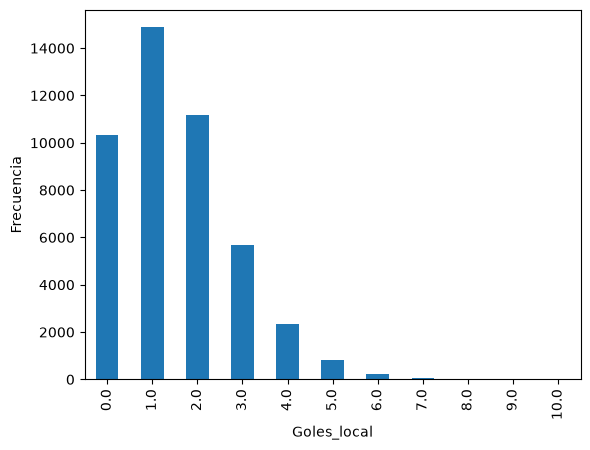

In [132]:
df["Goles_local"].value_counts().sort_index().plot(kind="bar", ylabel="Frecuencia")

**4.4** Haz lo mismo con otra columna de números.

<Axes: xlabel='Goles_visitante', ylabel='Frecuencia'>

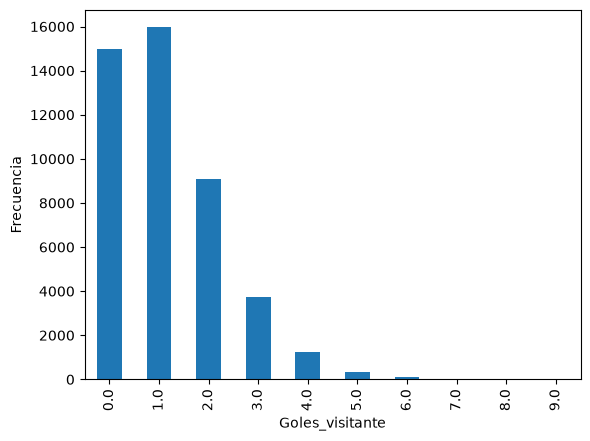

In [133]:
df["Goles_visitante"].value_counts().sort_index().plot(kind="bar", ylabel="Frecuencia")

Lo que he visto y lo que he decidido:

Hemos observado:
- Goles: los equipos locales marcan de media 1,53 goles y los visitantes 1,16.
- Tiros: los locales realizan de media 13,74 y los visitantes 11,04.
- Tiros a puerta: 5,23 frente a 4,16.
- Faltas: 13,60 frente a 14,04.
- Amarillas: 1,84 frente a 2,14.
- Rojas: 0,095 frente a 0,124.
- La media de goles locales (1,53) es superior a la mediana (1), lo que sugiere cierta asimetría hacia la derecha.
- Existen algunos valores máximos elevados, como 10 goles locales y 9 visitantes.

Decidimos:
- No modificar ninguna variable basándonos únicamente en describe().
- Utilizar gráficos de barras para representar la distribución de goles locales y visitantes, ya que son valores discretos.
- Conservar estas observaciones para analizarlas posteriormente y comprobar si existe una ventaja real de jugar en casa.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [134]:
df.nlargest(5, "Goles_local")

,Liga,Fecha,Equipo_local,Equipo_visitante,Elo_local,Elo_visitante,Goles_local,Goles_visitante,Resultado_final,Goles_descanso_local,...,Tiros_local,Tiros_visitante,Tiros_a_puerta_local,Tiros_a_puerta_visitante,Faltas_local,Faltas_visitante,Amarillas_local,Amarillas_visitante,Rojas_local,Rojas_visitante
119659,SP1,2015-12-20,Real Madrid,Vallecano,2015.26,1648.18,10.0,2.0,H,4.0,...,30.0,9.0,15.0,4.0,12.0,12.0,1.0,2.0,0.0,2.0
58001,E0,2009-11-22,Tottenham,Wigan,1749.04,1650.28,9.0,1.0,H,1.0,...,28.0,11.0,16.0,5.0,9.0,11.0,1.0,0.0,0.0,0.0
86895,D1,2013-03-30,Bayern Munich,Hamburg,1977.99,1694.29,9.0,2.0,H,5.0,...,25.0,10.0,15.0,8.0,6.0,14.0,0.0,0.0,0.0,0.0
111016,SP1,2015-04-05,Real Madrid,Granada,2045.67,1633.70,9.0,1.0,H,4.0,...,29.0,11.0,11.0,6.0,6.0,9.0,1.0,2.0,0.0,0.0
156962,F1,2019-01-19,Paris SG,Guingamp,1910.11,1482.35,9.0,0.0,H,3.0,...,26.0,2.0,12.0,0.0,11.0,7.0,1.0,0.0,0.0,0.0


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [135]:
df.nsmallest(5, "Goles_local")

,Liga,Fecha,Equipo_local,Equipo_visitante,Elo_local,Elo_visitante,Goles_local,Goles_visitante,Resultado_final,Goles_descanso_local,...,Tiros_local,Tiros_visitante,Tiros_a_puerta_local,Tiros_a_puerta_visitante,Faltas_local,Faltas_visitante,Amarillas_local,Amarillas_visitante,Rojas_local,Rojas_visitante
3,F1,2000-07-29,Auxerre,Sedan,1635.58,1624.22,0.0,1.0,A,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,F1,2000-07-29,Nantes,Lens,1664.36,1730.89,0.0,2.0,A,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,F1,2000-07-29,Toulouse,Bastia,1551.65,1656.37,0.0,1.0,A,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27,F1,2000-08-05,Strasbourg,Lille,1636.89,1632.15,0.0,4.0,A,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45,D1,2000-08-12,Kaiserslautern,Bochum,1669.80,1587.32,0.0,1.0,A,0.0,...,11.0,5.0,2.0,2.0,9.0,8.0,1.0,0.0,0.0,0.0


**5.3** Haz el diagrama de caja de esa columna.

<Axes: >

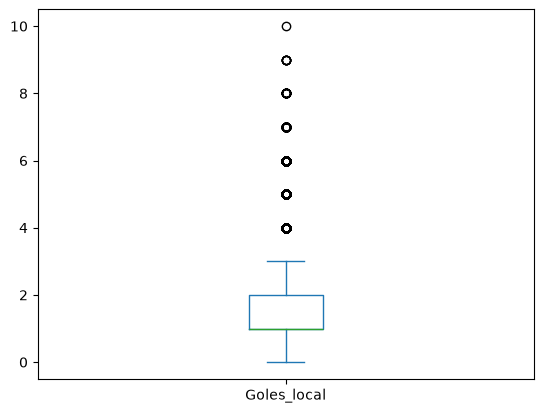

In [136]:
df["Goles_local"].plot(kind="box")

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido:

En nuestro diagrama de cajas aparecen varios valores atípicos (outliers): partidos en los que el equipo local marcó 4, 5, 6, 7, 8, 9 o 10 goles.


Los mantenemos por los siguientes motivos:
- Son resultados posibles en un partido de fútbol.
- No parecen errores por el simple hecho de ser valores extremos.
- El diagrama de cajas identifica observaciones poco habituales, pero no significa que sean incorrectas.


Conclusión: no eliminamos ningún registro. Un valor atípico no es necesariamente un error. En nuestro análisis queremos conservar los resultados reales, incluso los menos frecuentes.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [137]:
numero_resultados = df["Resultado_final"].value_counts()
porcentaje_resultados = df["Resultado_final"].value_counts(normalize = True) * 100

print(porcentaje_resultados)
print(numero_resultados)

Resultado_final
H    45.594956
A    28.535021
D    25.870024
Name: proportion, dtype: float64
Resultado_final
H    20753
A    12988
D    11775
Name: count, dtype: int64


**6.2** Dibújalo en barras.

<Axes: xlabel='Resultado_final', ylabel='Porcentaje'>

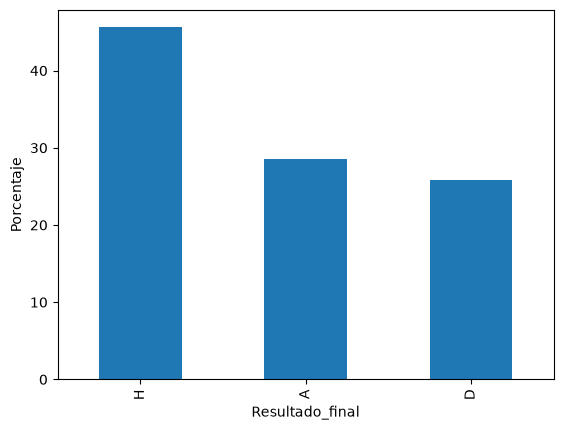

In [138]:
porcentaje_resultados.plot(kind="bar", ylabel="Porcentaje")

Lo que he visto y lo que he decidido:

Observamos que el porcentaje de victorias de los equipos locales es notablemente superior al de visitantes y a empates. 

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [143]:
df["Liga"] = df["Liga"].replace({
    "E0": "Premier League",
    "SP1": "LaLiga",
    "I1": "Serie A",
    "F1": "Ligue 1",
    "D1": "Bundesliga"
})


df.groupby("Liga")["Tiros_local"].mean()

Liga
Bundesliga        14.556910
LaLiga            13.695453
Ligue 1           13.216634
Premier League    13.629180
Serie A           13.653307
Name: Tiros_local, dtype: float64

**7.2** Haz otra comparación con otra columna de grupos.

In [142]:
df.groupby("Resultado_final")["Tiros_local"].mean()


Resultado_final
A    12.564702
D    13.464327
H    14.651126
Name: Tiros_local, dtype: float64

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [144]:
df.groupby("Resultado_final")["Tiros_local"].count()


Resultado_final
A    11808
D    10372
H    18425
Name: Tiros_local, dtype: int64

Lo que he visto y lo que he decidido:

Lo que hemos visto:
- Hemos elegido los tiros locales porque permiten estudiar mejor la relación entre el rendimiento ofensivo y el resultado del partido.
- Hemos calculado la media de tiros locales agrupando los partidos según el resultado final (victoria local, empate o victoria visitante).
- Hemos comprobado cuántos partidos hay en cada grupo:
   Victoria visitante (A): 11.808.
   Empate (D): 10.372.
   Victoria local (H): 18.425.
- Los tres grupos tienen suficientes observaciones para realizar una comparación descriptiva.

Lo que hemos decidido:
- Utilizar Tiros_local en lugar de Goles_local para esta segunda comparación.
- Mantener los valores ausentes sin imputarlos.
- No eliminar ningún grupo, ya que todos tienen un tamaño amplio.
- Utilizar los resultados para estudiar si existe una relación entre el número de tiros locales y el resultado final.

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [146]:
df["Tiros_local"].corr(df["Goles_local"]).round(2)

np.float64(0.26)

**8.2** Haz el gráfico de puntos de esas dos columnas.

<Axes: xlabel='Tiros_local', ylabel='Goles_local'>

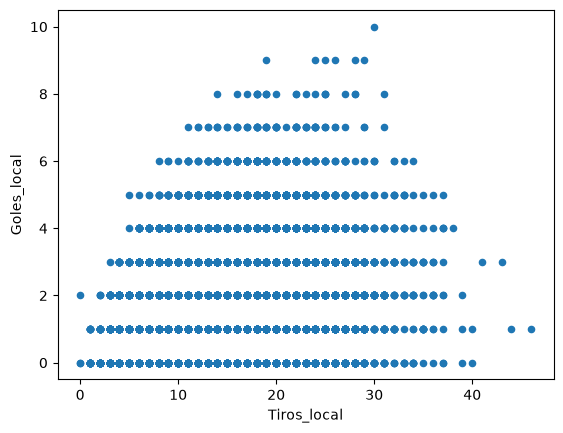

In [149]:
df.plot(kind="scatter", x="Tiros_local", y="Goles_local")




Lo que he visto y lo que he decidido:

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

Escribe aquí tus hallazgos:

1. Goles: Los equipos locales marcaron una media de 1,53 goles por partido, frente a los 1,16 de los visitantes.

2. Resultados: Se registraron 18.425 victorias locales, 11.808 victorias visitantes y 10.372 empates.

3. Correlación: Los tiros locales y los goles locales presentan una correlación positiva de 0,26, aunque débil.

Limpieza de datos: Eliminé los registros con valores ausentes en las columnas de Elo y resultados al descanso, sustituí los códigos de las ligas por sus nombres completos y conservé los valores ausentes de las estadísticas de tiros, faltas y tarjetas.


## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.

In [152]:
df.to_csv("datos_limpios.csv", index=False)